# Indian agriculture: national foodgrain production and seasonal split

The uploaded archive contains several small tables and a larger annual series table. This project uses `produce.csv`, with 429 source rows. It reshapes the national series into year-value observations and keeps units separate throughout. State-level descriptions are present elsewhere in the file, but they are not added to national aggregates.

## Data and scope

Source: [agricuture-crops-production-in-india](https://www.kaggle.com/datasets/srinivas1/agricuture-crops-production-in-india). This report uses the uploaded snapshot, not live data.

One source row is an annual statistical series. `Particulars` describes the measure, crop, season or geography; `Frequency` states the reporting frequency; `Unit` distinguishes million tonnes (`Ton mn`), thousand tonnes (`Ton th`), million hectares (`ha mn`), kg/ha and other units. Columns such as `3-2005` represent annual periods ending in March. After reshaping, `year` is the period-ending year and `value` is its reported measurement. Blank cells are missing, not zero.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

%matplotlib inline
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({"figure.figsize": (10, 5), "figure.dpi": 110,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_columns", 25)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

def data_path(filename):
    # Works after extracting this ZIP, or after attaching its data on Kaggle.
    for folder in (Path("data"), Path(".")):
        candidate = folder / filename
        if candidate.is_file():
            return candidate
    kaggle = Path("/kaggle/input")
    matches = sorted(kaggle.rglob(filename)) if kaggle.exists() else []
    if len(matches) == 1:
        return matches[0]
    raise FileNotFoundError(f"Place {filename} in data/, or attach its dataset on Kaggle. Found {len(matches)} Kaggle matches.")

In [2]:
raw = pd.read_csv(data_path("produce.csv"))
print(f"Source table: {len(raw):,} rows, {raw.shape[1]} columns")
assert len(raw)>=150 and raw.shape[1]>=3
display(raw.head()); display(raw.isna().sum().to_frame("missing"))
display(raw.Unit.value_counts().to_frame("series"))

Source table: 429 rows, 25 columns


,Particulars,Frequency,Unit,3-1993,3-1994,3-1995,3-1996,3-1997,3-1998,3-1999,3-2000,3-2001,3-2002,3-2003,3-2004,3-2005,3-2006,3-2007,3-2008,3-2009,3-2010,3-2011,3-2012,3-2013,3-2014
0,Agricultural Production Foodgrains,"Annual, Ending mar Of Each Year",Ton mn,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,198.363,208.602,217.282,230.775,234.466,218.107,244.492,259.286,257.130,264.381
1,Agricultural Production Foodgrains Kharif,"Annual, Ending mar Of Each Year",Ton mn,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,103.309,109.873,110.576,120.957,118.139,103.954,120.853,131.275,128.070,129.369
2,Agricultural Production Foodgrains Rabi,"Annual, Ending mar Of Each Year",Ton mn,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,95.053,98.728,106.706,109.818,116.328,114.153,123.639,128.011,129.060,135.012
3,Agricultural Production Foodgrains Rice,"Annual, Ending mar Of Each Year",Ton mn,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,83.132,91.793,93.355,96.693,99.183,89.093,95.980,105.301,105.240,106.287
4,Agricultural Production Foodgrains Rice Kharif,"Annual, Ending mar Of Each Year",Ton mn,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,72.230,78.272,80.171,82.659,84.908,75.917,80.651,92.781,92.370,92.009


,missing
Particulars,0
Frequency,0
Unit,0
3-1993,426
3-1994,425
3-1995,425
3-1996,423
3-1997,419
3-1998,419
3-1999,418


,series
Unit,
Ton mn,125
ha mn,108
kg/ha,104
Ton th,86
Bale mn,4
Unit mn,1
%,1



`melt()` converts year columns into rows, making time comparisons easier. `to_numeric()` exposes nonnumeric measurements as missing. Negative agricultural quantities are invalid here and are set to missing. No forward filling is used. The helper below selects one exact series description and unit; it refuses ambiguous matches. This avoids accidentally combining production with area, yield, targets or state breakdowns.

Negative values made missing: 0


,count,min,median,max
Unit,,,,
%,10,40.000,42.600,44.200
Bale mn,40,0.580,10.678,36.500
Ton mn,1244,0.087,12.593,361.037
Ton th,860,0.000,494.050,"30,300.000"
Unit mn,10,"12,129.000","12,657.000","14,811.000"
ha mn,1074,0.045,3.692,126.670
kg/ha,1034,201.000,"1,713.000","69,202.000"


,size,count
year,,
1993,429,3
1994,429,4
1995,429,4
1996,429,6
1997,429,10
1998,429,10
1999,429,11
2000,429,20
2001,429,22


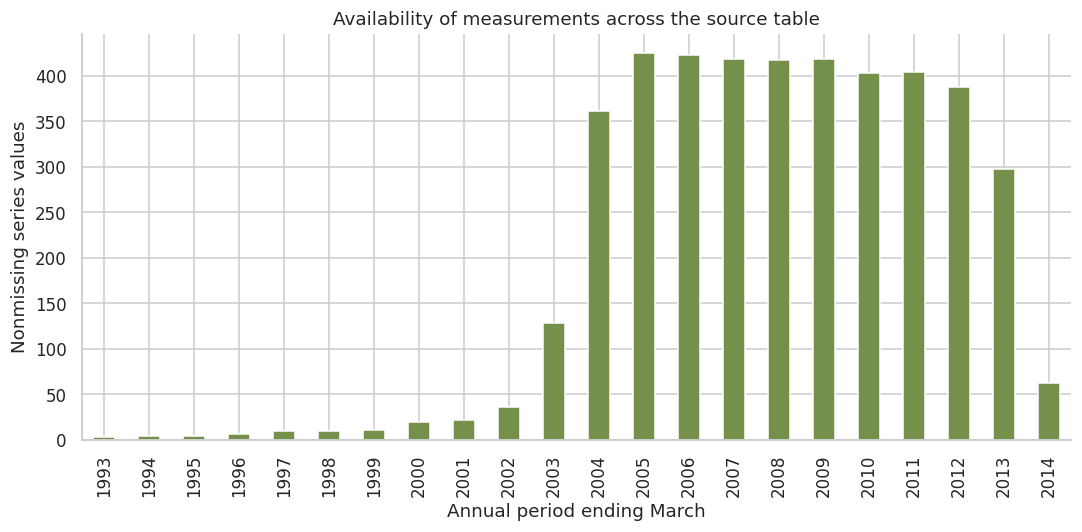

In [3]:
df = raw.drop_duplicates().copy()
df.columns = df.columns.str.strip()
for col in ["Particulars","Frequency","Unit"]:
    df[col] = df[col].str.strip()
assert not df.duplicated(["Particulars","Unit"]).any()
year_cols = [c for c in df.columns if c.startswith("3-")]
long = df.melt(id_vars=["Particulars","Frequency","Unit"],value_vars=year_cols,var_name="period",value_name="value")
long["year"] = long.period.str.split("-").str[-1].astype(int)
long["value"] = pd.to_numeric(long.value,errors="coerce")
print(f"Negative values made missing: {long.value.lt(0).sum()}")
long.loc[long.value.lt(0),"value"] = np.nan
display(long.groupby("Unit").value.agg(["count","min","median","max"]))
display(long.groupby("year").value.agg(["size","count"]))

def series(description, unit):
    selected = long[(long.Particulars==description) & (long.Unit==unit)]
    assert len(selected)==len(year_cols), description
    return selected.set_index("year").value.sort_index()

coverage = long.groupby("year").value.count()
coverage.plot.bar(color="#74904b")
plt.xlabel("Annual period ending March"); plt.ylabel("Nonmissing series values")
plt.title("Availability of measurements across the source table"); plt.tight_layout(); plt.show()

## 1. How has national foodgrain production changed?

The exact national foodgrain production series is used, in million tonnes. `dropna()` identifies the available endpoints. Endpoint percentage change is reported alongside the actual years; it is not assumed to span every year in the file.

,foodgrains_million_tonnes
year,
2005,198.363
2006,208.602
2007,217.282
2008,230.775
2009,234.466
2010,218.107
2011,244.492
2012,259.286
2013,257.130


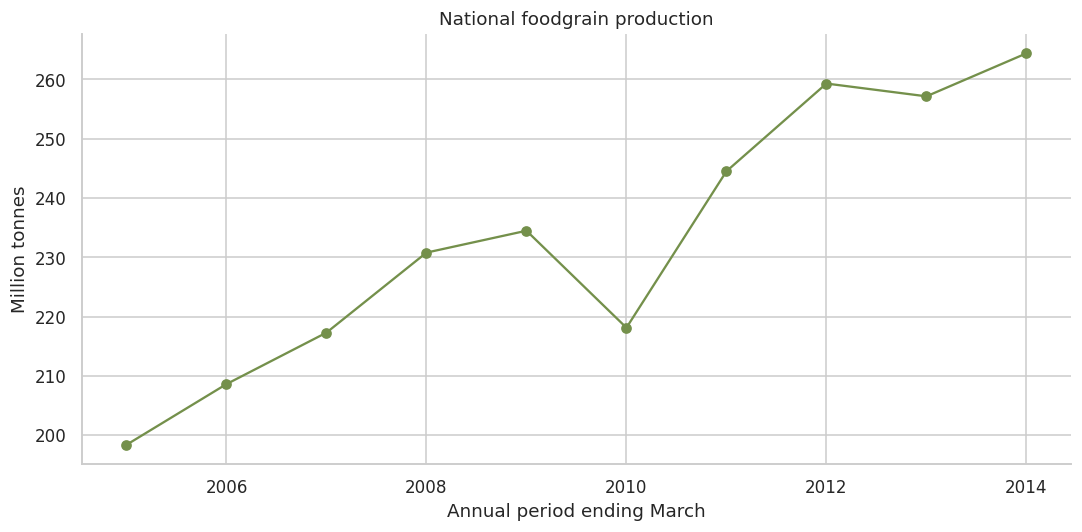

In [4]:
food = series("Agricultural Production Foodgrains","Ton mn").dropna()
food_change = (food.iloc[-1]/food.iloc[0]-1)*100
display(food.to_frame("foodgrains_million_tonnes"))
food.plot(marker="o",color="#74904b")
plt.xlabel("Annual period ending March"); plt.ylabel("Million tonnes")
plt.title("National foodgrain production"); plt.tight_layout(); plt.show()

**Answer.** Recorded foodgrain production moves from 198.36 million tonnes in the period ending March 2005 to 264.38 million tonnes in March 2014, a change of 33.3%. Only 10 annual observations are available for this series.

## 2. How do Kharif and Rabi foodgrain production compare?

`concat()` aligns the two seasonal series by year. Both use the same production unit. Their sum is checked against the national total, rather than assuming the source series reconcile exactly.

,Kharif,Rabi,Kharif_share_pct,difference_from_total
year,,,,
2005,103.309,95.053,52.081,0.000
2006,109.873,98.728,52.671,0.000
2007,110.576,106.706,50.891,0.000
2008,120.957,109.818,52.413,0.000
2009,118.139,116.328,50.386,0.000
2010,103.954,114.153,47.662,0.000
2011,120.853,123.639,49.430,0.000
2012,131.275,128.011,50.629,0.000
2013,128.070,129.060,49.807,0.000


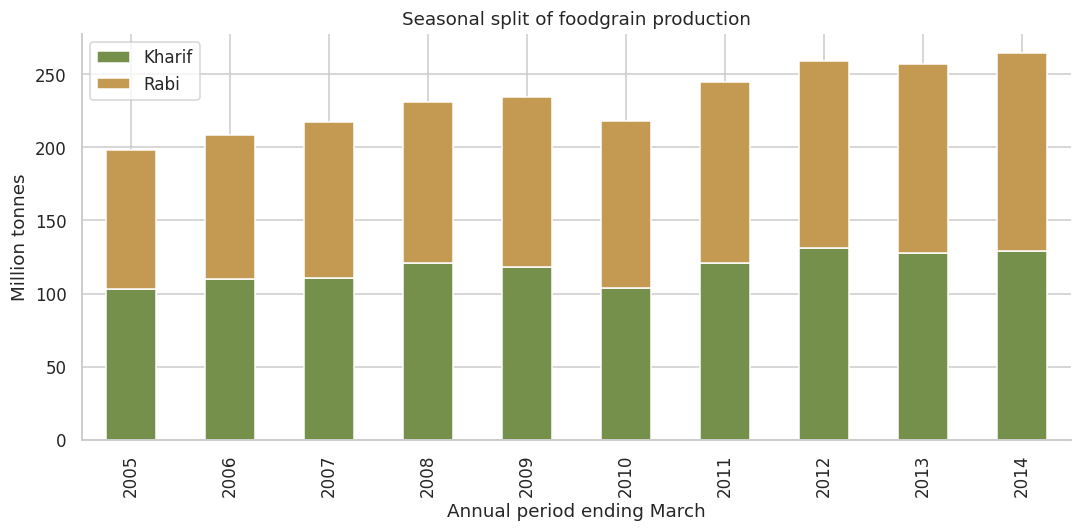

In [5]:
seasons = pd.concat({"Kharif":series("Agricultural Production Foodgrains Kharif","Ton mn"),"Rabi":series("Agricultural Production Foodgrains Rabi","Ton mn")},axis=1).dropna()
seasons["Kharif_share_pct"] = seasons.Kharif/(seasons.Kharif+seasons.Rabi)*100
seasons["difference_from_total"] = seasons.Kharif+seasons.Rabi-food.reindex(seasons.index)
display(seasons)
seasons[["Kharif","Rabi"]].plot.bar(stacked=True,color=["#74904b","#c49a53"])
plt.xlabel("Annual period ending March"); plt.ylabel("Million tonnes"); plt.title("Seasonal split of foodgrain production")
plt.tight_layout(); plt.show()

**Answer.** In 2014, Kharif contributes 129.37 million tonnes and Rabi 135.01 million tonnes. Kharif represents 48.9% of their combined output. The largest absolute seasonal-sum difference from the national series is 0.0000 million tonnes.

## 3. How do rice, wheat, maize and pulses compare in the latest shared year?

Exact national crop series are selected. Wheat is labelled Rabi in the source. These crops are compared in million tonnes, and a year must have all four values to be included. They are not summed with the foodgrain total because that would double count components.

,Rice,Wheat (Rabi),Maize,Pulses
year,,,,
2005,83.132,68.637,14.172,13.130
2006,91.793,69.355,14.710,13.384
2007,93.355,75.807,15.097,14.198
2008,96.693,78.570,18.955,14.762
2009,99.183,80.679,19.731,14.566
2010,89.093,80.804,16.719,14.662
2011,95.980,86.874,21.726,18.241
2012,105.301,94.882,21.759,17.089
2013,105.240,93.510,22.260,18.340


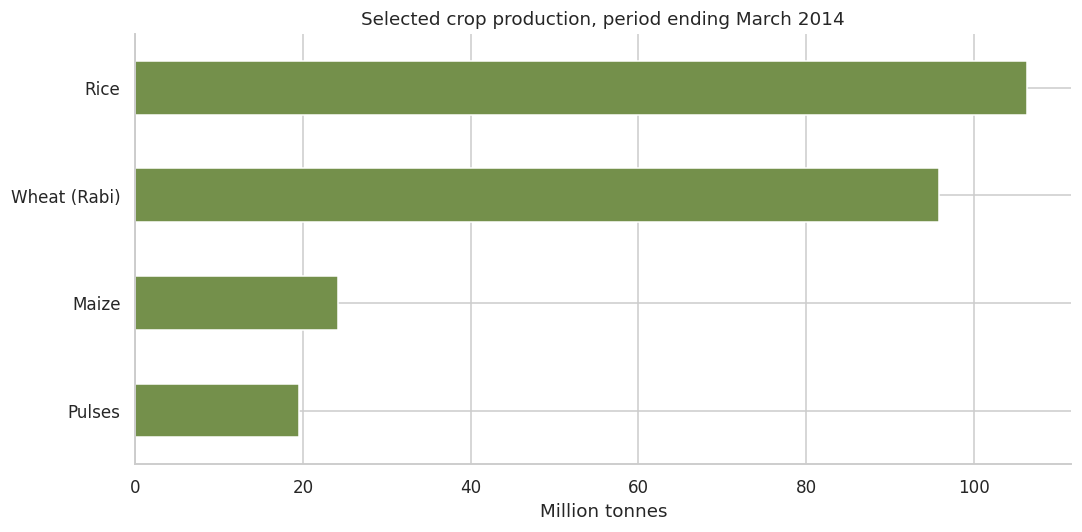

In [6]:
crop_names = {"Rice":"Agricultural Production Foodgrains Rice","Wheat (Rabi)":"Agricultural Production Foodgrains Wheat Rabi","Maize":"Agricultural Production Foodgrains Maize","Pulses":"Agricultural Production Foodgrains Pulses"}
crops = pd.concat({name:series(label,"Ton mn") for name,label in crop_names.items()},axis=1).dropna()
last_crops = crops.iloc[-1].sort_values(ascending=False)
display(crops)
last_crops.sort_values().plot.barh(color="#74904b")
plt.xlabel("Million tonnes"); plt.title(f"Selected crop production, period ending March {crops.index[-1]}")
plt.tight_layout(); plt.show()

**Answer.** Rice has the largest reported production among the selected crops in 2014, at 106.29 million tonnes. This compares physical output; it says nothing about crop prices, nutritional value or farm profitability.

## 4. Which selected crop series changed most relative to its starting level?

`div()` rebases each crop to 100 in the first year when all four are reported. This allows relative change to be compared without the largest-tonnage crop dominating the chart. A low starting value can make a percentage change look large.

,change_pct
Maize,70.695
Pulses,49.038
Wheat (Rabi),39.647
Rice,27.854


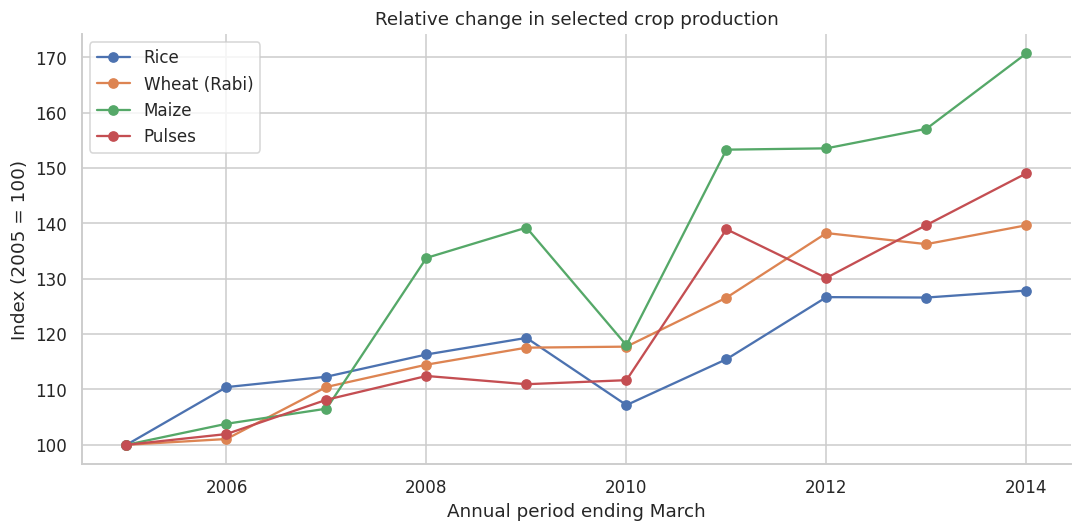

In [7]:
indexed = crops.div(crops.iloc[0]).mul(100)
relative_change = (indexed.iloc[-1]-100).sort_values(ascending=False)
display(relative_change.to_frame("change_pct"))
indexed.plot(marker="o")
plt.xlabel("Annual period ending March"); plt.ylabel(f"Index ({crops.index[0]} = 100)")
plt.title("Relative change in selected crop production"); plt.tight_layout(); plt.show()

**Answer.** Maize has the largest endpoint increase among the four selected series (70.7%) between 2005 and 2014. The full path matters: an endpoint change can conceal intervening falls and recoveries.

## 5. Which national foodgrain years show the largest year-to-year changes?

`pct_change(fill_method=None)` compares adjacent annual entries without filling gaps. Both the previous and current year must be observed. The calculation uses the untrimmed series so missing years cannot be silently skipped.

,year_on_year_pct
year,
2006,5.162
2007,4.161
2008,6.210
2009,1.599
2010,-6.977
2011,12.097
2012,6.051
2013,-0.832
2014,2.820


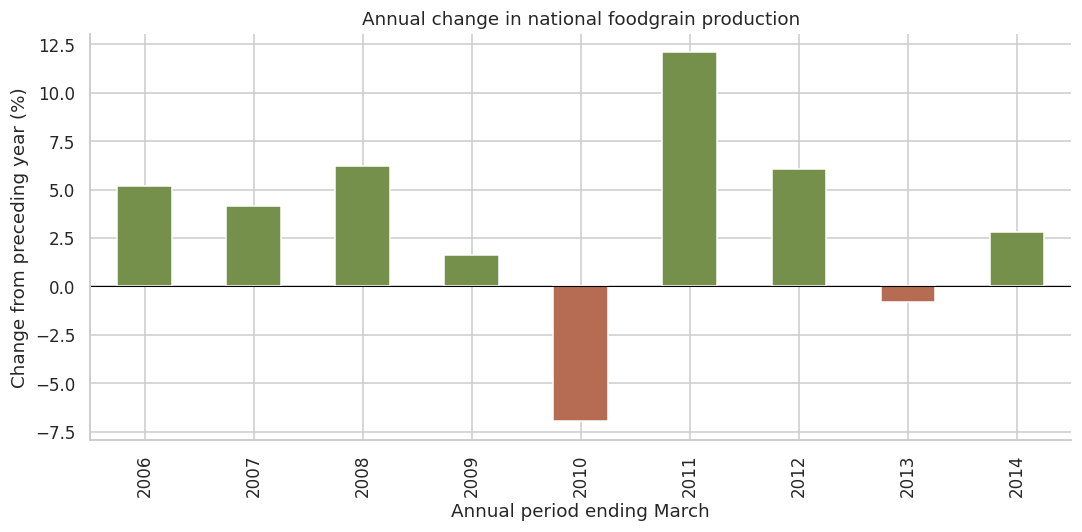

In [8]:
full_food = series("Agricultural Production Foodgrains","Ton mn")
growth = full_food.pct_change(fill_method=None).mul(100).dropna()
display(growth.to_frame("year_on_year_pct"))
growth.plot.bar(color=["#74904b" if x>=0 else "#b66c52" for x in growth])
plt.axhline(0,color="black",lw=.7); plt.xlabel("Annual period ending March")
plt.ylabel("Change from preceding year (%)"); plt.title("Annual change in national foodgrain production")
plt.tight_layout(); plt.show()

**Answer.** The largest increase is in 2011 (12.1%) and the weakest annual change is in 2010 (-7.0%). These movements identify periods worth investigating, but the file alone cannot explain whether weather, acreage, inputs or reporting revisions caused them.

## Conclusion

National foodgrain output increases by 33.3% between the periods ending March 2005 and March 2014. Maize has the largest relative increase among the four selected crop series at 70.7%, while total foodgrain production falls by 7.0% in the period ending March 2010.

The national series show changes in overall output, differences between the two seasons and unequal growth across selected crops. Reshaping the data makes those comparisons possible, while exact series matching prevents aggregate totals and their components from being counted together.
